# COMP813 — Notebook 08: BiLSTM Sequence-Length Ablation

**Purpose:** Examine the sensitivity of the saved BiLSTM model to the amount of input context available at inference time on the unseen CEAS-08 dataset.

This is a controlled **inference-time ablation**: the trained model and all learned parameters are held fixed, while the maximum number of tokens supplied to the model is varied. This is intentionally distinguished from retraining separate models, so any differences should be interpreted as sensitivity to available input context rather than as evidence about how a differently trained model would perform.

**Configurations:** 100, 250 and 500 tokens.

**Primary questions**
1. How does CEAS-08 performance change as more email context is retained?
2. Does the BiLSTM's false-negative pattern change with the input limit?
3. How much prediction instability is introduced by reducing the available context?

In [1]:
import os
import re
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

SEED = 813
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [2]:
# Load CEAS-08
ceas_df = pd.read_csv("ceas08_clean.csv")

X_ceas = ceas_df["text"].astype(str)
y_ceas = ceas_df["label"].to_numpy()

print("CEAS-08 size:", len(ceas_df))
print("Class distribution:")
print(pd.Series(y_ceas).value_counts().sort_index())

CEAS-08 size: 38964
Class distribution:
0    17290
1    21674
Name: count, dtype: int64


In [3]:
def tokenize_text(text):
    return re.findall(r"\b\w+\b", text.lower())

with open("../models/bilstm_vocabulary.json", "r", encoding="utf-8") as f:
    vocab = json.load(f)

checkpoint = torch.load(
    "../models/bilstm_enron.pt",
    map_location=device
)

print("Vocabulary size:", len(vocab))
print("Saved vocabulary size:", checkpoint["vocab_size"])
print("Embedding dimension:", checkpoint["embedding_dim"])
print("Hidden dimension:", checkpoint["hidden_dim"])
print("Saved maximum sequence length:", checkpoint["max_sequence_length"])

Vocabulary size: 50000
Saved vocabulary size: 50000
Embedding dimension: 128
Hidden dimension: 128
Saved maximum sequence length: 500


In [4]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, dropout):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, 1)

    def forward(self, x):
        embedded = self.embedding(x)
        output, (hidden, cell) = self.lstm(embedded)

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined_hidden = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        combined_hidden = self.dropout(combined_hidden)
        output = self.fc(combined_hidden)

        return output.squeeze(1)


bilstm_model = BiLSTMClassifier(
    vocab_size=checkpoint["vocab_size"],
    embedding_dim=checkpoint["embedding_dim"],
    hidden_dim=checkpoint["hidden_dim"],
    dropout=checkpoint["dropout"]
)

bilstm_model.load_state_dict(checkpoint["model_state_dict"])
bilstm_model.to(device)
bilstm_model.eval()

print("BiLSTM checkpoint loaded successfully.")

BiLSTM checkpoint loaded successfully.


In [5]:
def text_to_sequence(text, max_length):
    tokens = tokenize_text(text)

    sequence = [
        vocab.get(token, vocab.get("<UNK>", 1))
        for token in tokens[:max_length]
    ]

    if len(sequence) < max_length:
        sequence += [
            vocab.get("<PAD>", 0)
        ] * (max_length - len(sequence))

    return sequence


def bilstm_predict(texts, max_length, batch_size=256):
    sequences = np.array(
        [text_to_sequence(text, max_length) for text in texts],
        dtype=np.int64
    )

    tensor_x = torch.tensor(
        sequences,
        dtype=torch.long
    )

    loader = DataLoader(
        TensorDataset(tensor_x),
        batch_size=batch_size,
        shuffle=False
    )

    predictions = []

    with torch.no_grad():
        for (batch_x,) in loader:
            batch_x = batch_x.to(device)
            logits = bilstm_model(batch_x)
            batch_predictions = (
                torch.sigmoid(logits) >= 0.5
            ).long()
            predictions.extend(
                batch_predictions.cpu().numpy()
            )

    return np.array(predictions)

In [6]:
# Run the sequence-length ablation
sequence_lengths = [100, 250, 500]

ablation_results = []
predictions_by_length = {}

for max_length in sequence_lengths:
    predictions = bilstm_predict(
        X_ceas,
        max_length=max_length
    )

    predictions_by_length[max_length] = predictions

    tn, fp, fn, tp = confusion_matrix(
        y_ceas,
        predictions,
        labels=[0, 1]
    ).ravel()

    ablation_results.append({
        "max_sequence_length": max_length,
        "accuracy": accuracy_score(y_ceas, predictions),
        "precision": precision_score(y_ceas, predictions, zero_division=0),
        "recall": recall_score(y_ceas, predictions, zero_division=0),
        "f1": f1_score(y_ceas, predictions, zero_division=0),
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
        "true_negatives": tn
    })

    print(
        f"{max_length} tokens -> "
        f"Accuracy={ablation_results[-1]['accuracy']:.4f}, "
        f"F1={ablation_results[-1]['f1']:.4f}, "
        f"FP={fp}, FN={fn}"
    )

ablation_df = pd.DataFrame(ablation_results)
ablation_df

100 tokens -> Accuracy=0.6065, F1=0.7280, FP=14173, FN=1158
250 tokens -> Accuracy=0.5862, F1=0.7078, FP=13982, FN=2142
500 tokens -> Accuracy=0.5654, F1=0.6865, FP=13800, FN=3134


,max_sequence_length,accuracy,precision,recall,f1,false_positives,false_negatives,true_positives,true_negatives
0,100,0.606534,0.591427,0.946572,0.727995,14173,1158,20516,3117
1,250,0.586182,0.582801,0.901172,0.707835,13982,2142,19532,3308
2,500,0.565394,0.573284,0.855403,0.686489,13800,3134,18540,3490


In [7]:
# Verify that the 500-token configuration reproduces the main BiLSTM result
baseline_500 = ablation_df[
    ablation_df["max_sequence_length"] == 500
].iloc[0]

print("500-token confusion matrix:")
print(
    confusion_matrix(
        y_ceas,
        predictions_by_length[500],
        labels=[0, 1]
    )
)

print("\n500-token F1:", round(baseline_500["f1"], 4))
print("Expected main CEAS-08 F1: approximately 0.6865")

500-token confusion matrix:
[[ 3490 13800]
 [ 3134 18540]]

500-token F1: 0.6865
Expected main CEAS-08 F1: approximately 0.6865


## Prediction stability relative to the 500-token baseline

Reducing the sequence limit can change individual predictions even when the underlying model weights are unchanged. The next analysis measures how often each shorter configuration disagrees with the 500-token baseline.

In [8]:
stability_rows = []
baseline_predictions = predictions_by_length[500]

for max_length in [100, 250]:
    shorter_predictions = predictions_by_length[max_length]

    changed = (
        shorter_predictions != baseline_predictions
    )

    stability_rows.append({
        "max_sequence_length": max_length,
        "changed_predictions": int(changed.sum()),
        "prediction_change_rate": changed.mean()
    })

stability_df = pd.DataFrame(stability_rows)
stability_df

,max_sequence_length,changed_predictions,prediction_change_rate
0,100,2665,0.068396
1,250,1314,0.033723


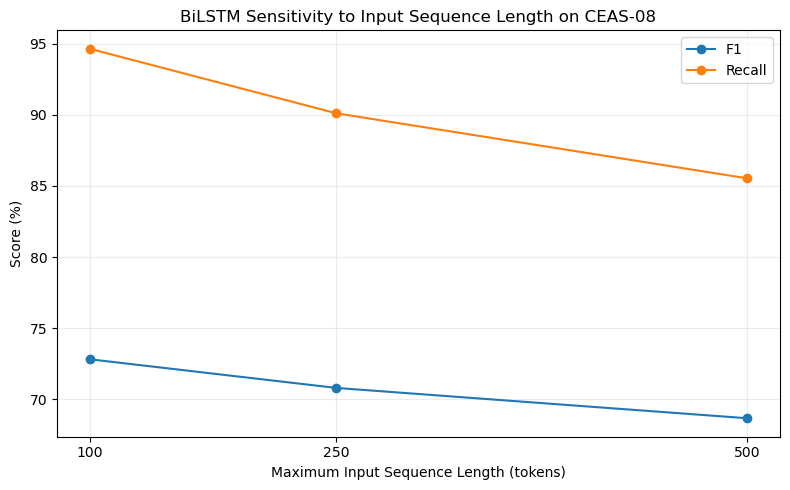

In [9]:
# Plot F1 and recall against available input context
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    ablation_df["max_sequence_length"],
    ablation_df["f1"] * 100,
    marker="o",
    label="F1"
)

ax.plot(
    ablation_df["max_sequence_length"],
    ablation_df["recall"] * 100,
    marker="o",
    label="Recall"
)

ax.set_xlabel("Maximum Input Sequence Length (tokens)")
ax.set_ylabel("Score (%)")
ax.set_title("BiLSTM Sensitivity to Input Sequence Length on CEAS-08")
ax.set_xticks(sequence_lengths)
ax.grid(True, alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

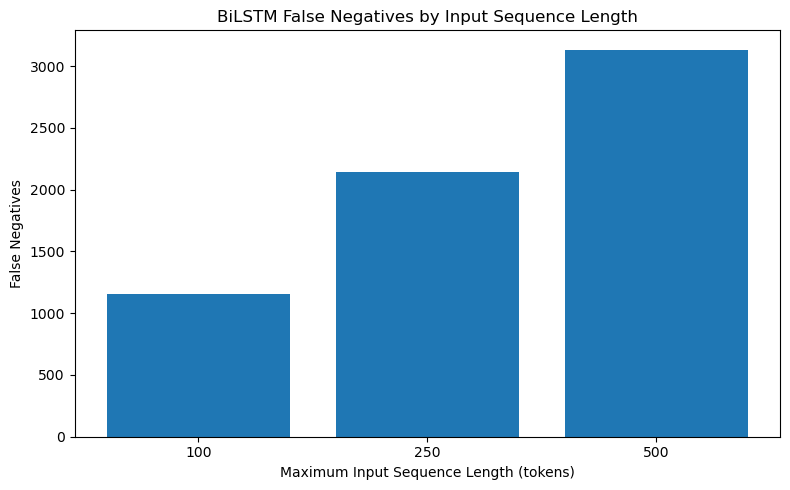

In [10]:
# Plot false negatives
plt.figure(figsize=(8, 5))
plt.bar(
    ablation_df["max_sequence_length"].astype(str),
    ablation_df["false_negatives"]
)
plt.xlabel("Maximum Input Sequence Length (tokens)")
plt.ylabel("False Negatives")
plt.title("BiLSTM False Negatives by Input Sequence Length")
plt.tight_layout()
plt.show()

In [11]:
# Save results
os.makedirs("../results", exist_ok=True)

ablation_df.to_csv(
    "../results/bilstm_sequence_length_ablation.csv",
    index=False
)

stability_df.to_csv(
    "../results/bilstm_sequence_length_prediction_stability.csv",
    index=False
)

print("Saved:")
print("../results/bilstm_sequence_length_ablation.csv")
print("../results/bilstm_sequence_length_prediction_stability.csv")

Saved:
../results/bilstm_sequence_length_ablation.csv
../results/bilstm_sequence_length_prediction_stability.csv


## Interpretation guide

The 500-token setting is the original trained model configuration and therefore acts as the reference condition. The 100- and 250-token settings are inference-time context ablations using the same learned parameters.

When interpreting the results:

- A performance reduction at shorter limits indicates sensitivity to removing later tokens from the input.
- A reduction in false negatives as the sequence limit increases would be consistent with the error-analysis finding that many BiLSTM false negatives occur in long emails.
- Prediction-change rates quantify how often reducing context changes the model's decision.
- This experiment **does not establish the effect of retraining at each sequence length**, because the model weights are held fixed.

This limitation should be stated explicitly in the report.